In [66]:
import numpy as np
import math
import scipy.integrate as spi
import matplotlib.pyplot as plt


"""
Преднастройки
"""

Y_cell_size = 2*1e3 # Aperture is 1 mm
aperture = Y_cell_size # actual size in micrometers of lens
orders = 1 # the number of radial layers.
stack = 0 # N must be even., 0 - 2 - 4 - 6 - 8 - 10
LIMIT_PRODUCT = 0.2 # Limitation 200 nm. Geometry can't be larger this size.
f = 5*1e3 # focal length 5 mm
Q = 100 # curve detailing. It has almost no effect on the result
w = 0.1 # 200 nm. The width of the gap between the curves
wavelength = 4.25
k = 2 * np.pi / wavelength # wave number


def calculate_radii (D, f, wavelength, orders):
    """
    Вычисляет радиусы на поверхности линзы, на которых происходит полный фазовый сдвиг от 0 до 2Pi.

    :param D (float): Диаметр линзы.
    :param f (float): Фокусное расстояние линзы.
    :param wavelength (float): Длина волны света.
    :param orders (int): Максимальное значение n для расчета радиусов.
    :return: radii (list): Список радиусов.
    """
    radii = []
    for n in range(1, orders + 1):
        r = np.sqrt((n * wavelength)**2 + 2 * n * wavelength * f)
        if r <= D / 2:  # Проверяем, чтобы радиус не превышал радиус линзы
            radii.append(r)
        else:
            break  # Прекращаем расчет, если радиус превышает размер линзы
    return radii

def function (x):
    """
    :param x: координата х 
    :param W: ширина между кривыми
    """
    W = 1   
    return (W / math.pi) * math.log(abs(1 / math.cos((math.pi * x) / W)))

In [71]:
rt = [100]
for m in range(orders):
    rt0 = 0 if m == 0 else rt[m - 1] + 0.1
    x = np.linspace(rt0, rt[m]-0.001, Q)
    y = np.zeros_like(x)
    # Compute y values by integration
    for i in range (Q):
        y[i] = function(x[i])

In [72]:
x

array([ 0.        ,  1.01009091,  2.02018182,  3.03027273,  4.04036364,
        5.05045455,  6.06054545,  7.07063636,  8.08072727,  9.09081818,
       10.10090909, 11.111     , 12.12109091, 13.13118182, 14.14127273,
       15.15136364, 16.16145455, 17.17154545, 18.18163636, 19.19172727,
       20.20181818, 21.21190909, 22.222     , 23.23209091, 24.24218182,
       25.25227273, 26.26236364, 27.27245455, 28.28254545, 29.29263636,
       30.30272727, 31.31281818, 32.32290909, 33.333     , 34.34309091,
       35.35318182, 36.36327273, 37.37336364, 38.38345455, 39.39354545,
       40.40363636, 41.41372727, 42.42381818, 43.43390909, 44.444     ,
       45.45409091, 46.46418182, 47.47427273, 48.48436364, 49.49445455,
       50.50454545, 51.51463636, 52.52472727, 53.53481818, 54.54490909,
       55.555     , 56.56509091, 57.57518182, 58.58527273, 59.59536364,
       60.60545455, 61.61554545, 62.62563636, 63.63572727, 64.64581818,
       65.65590909, 66.666     , 67.67609091, 68.68618182, 69.69

In [73]:
y

array([0.00000000e+00, 1.59975406e-04, 6.40223548e-04, 1.44171279e-03,
       2.56606578e-03, 4.01557264e-03, 5.79320977e-03, 7.90266461e-03,
       1.03483667e-02, 1.31355258e-02, 1.62701775e-02, 1.97592376e-02,
       2.36105659e-02, 2.78330408e-02, 3.24366469e-02, 3.74325763e-02,
       4.28333475e-02, 4.86529434e-02, 5.49069726e-02, 6.16128586e-02,
       6.87900611e-02, 7.64603379e-02, 8.46480539e-02, 9.33805486e-02,
       1.02688576e-01, 1.12606832e-01, 1.23174596e-01, 1.34436507e-01,
       1.46443523e-01, 1.59254103e-01, 1.72935696e-01, 1.87566605e-01,
       2.03238388e-01, 2.20058947e-01, 2.38156599e-01, 2.57685487e-01,
       2.78832935e-01, 3.01829618e-01, 3.26963971e-01, 3.54603144e-01,
       3.85224415e-01, 4.19464058e-01, 4.58196740e-01, 5.02671671e-01,
       5.54762422e-01, 6.17467570e-01, 6.96042181e-01, 8.01046811e-01,
       9.59331375e-01, 1.28918604e+00, 1.35247695e+00, 9.80352658e-01,
       8.13639723e-01, 7.05018403e-01, 6.24430063e-01, 5.60439652e-01,
      

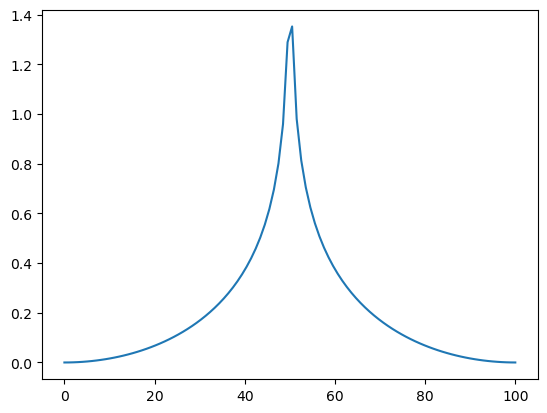

In [74]:
plt.plot(x, y)